# Huấn luyện Mô hình Phát hiện Xâm nhập Mạng (ML & DL NIDS)

Notebook này thực hiện huấn luyện và đánh giá toàn diện các mô hình **Machine Learning** và **Deep Learning** cho bài toán phát hiện xâm nhập mạng (Network Intrusion Detection System - NIDS), bám sát lộ trình từ **STEP 6 đến STEP 8** của dự án.

### Nội dung chính trong Notebook:
1. **Thiết lập môi trường & Dữ liệu:** Hỗ trợ nạp dữ liệu sạch từ Parquet (CIC-IDS-2017) hoặc tự động sinh Synthetic Benchmark Data nếu chưa tải dataset.
2. **STEP 6 - Phát hiện bất thường (Anomaly Detection - Unsupervised / Semi-supervised):**
   - Mô hình phân phối Gaussian (Log-Likelihood scoring)
   - Isolation Forest
3. **STEP 7 - Phân loại có giám sát (Supervised Classification):**
   - Random Forest Classifier (Multi-class, xử lý class imbalance)
   - Gradient Boosting / XGBoost Classifier
4. **STEP 8 - Deep Learning với PyTorch:**
   - Deep Autoencoder (học tái tạo lưu lượng BENIGN, phát hiện bất thường qua Reconstruction Error)
   - Multi-Layer Perceptron (MLP Classifier) phân loại tấn công đa lớp
5. **So sánh mô hình & Lưu trữ:**
   - Bảng tổng kết số liệu (Accuracy, Precision, Recall, Macro-F1, ROC-AUC, FPR, Inference Time)
   - Biểu đồ trực quan hóa so sánh
   - Xuất mô hình ra thư mục `saved_models/` để sử dụng cho module phát hiện thời gian thực (`realtime/`).

## 1. Khởi tạo môi trường & Cấu hình hệ thống

In [1]:
import os
import sys
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.ensemble import IsolationForest, RandomForestClassifier
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAS_XGB = False

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, confusion_matrix,
    classification_report
)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Đặt style cho biểu đồ
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 10
plt.rcParams['figure.titlesize'] = 12

# Cố định random seed
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Chọn thiết bị tính toán cho PyTorch (ưu tiên GPU nếu có, ngược lại CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[+] Scikit-Learn version: {sklearn.__version__}")
print(f"[+] PyTorch version: {torch.__version__} (Device: {device})")
print(f"[+] Gradient Boosting backend: {'XGBoost' if HAS_XGB else 'HistGradientBoostingClassifier (fallback)'}")

[+] Scikit-Learn version: 1.8.0
[+] PyTorch version: 2.14.1+cpu (Device: cpu)
[+] Gradient Boosting backend: HistGradientBoostingClassifier (fallback)


## 2. Nạp và Chuẩn bị dữ liệu (Data Pipeline)
Kiểm tra xem dữ liệu sạch `processed/cic/cicids2017_clean.parquet` đã tồn tại chưa. Nếu chưa, notebook tự động sinh **Synthetic Benchmark Dataset** tuân thủ đúng chuẩn đặc trưng của CIC-IDS-2017 để có thể chạy thử nghiệm ngay lập tức.

In [2]:
# Đường dẫn file dữ liệu sạch
PROJECT_ROOT = Path("..").resolve()
CLEAN_DATA_PATH = PROJECT_ROOT / "processed" / "cic" / "cicids2017_clean.parquet"
SAVED_MODELS_DIR = PROJECT_ROOT / "saved_models"
SAVED_MODELS_DIR.mkdir(parents=True, exist_ok=True)

def generate_synthetic_data(n_samples=25000, seed=42):
    """Tạo dữ liệu mô phỏng chuẩn CIC-IDS-2017 cho mục đích phát triển và kiểm thử."""
    rng = np.random.default_rng(seed)
    classes = ['BENIGN', 'DoS', 'DDoS', 'PortScan', 'BruteForce', 'Bot']
    weights = [0.65, 0.12, 0.10, 0.08, 0.03, 0.02]  # Tỷ lệ bất cân bằng mẫu thực tế
    labels = rng.choice(classes, size=n_samples, p=weights)
    
    # Danh sách các đặc trưng tiêu biểu trong CICFlowMeter
    feature_names = [
        'flow_duration', 'tot_fwd_pkts', 'tot_bwd_pkts', 'totlen_fwd_pkts',
        'totlen_bwd_pkts', 'fwd_pkt_len_max', 'fwd_pkt_len_min', 'fwd_pkt_len_mean',
        'bwd_pkt_len_mean', 'flow_byts_s', 'flow_pkts_s', 'flow_iat_mean',
        'flow_iat_std', 'flow_iat_max', 'fwd_iat_tot', 'bwd_iat_tot',
        'fwd_psh_flags', 'syn_flag_cnt', 'rst_flag_cnt', 'ack_flag_cnt',
        'pkt_len_mean', 'pkt_len_std', 'subflow_fwd_pkts', 'subflow_bwd_pkts'
    ]
    
    X = np.zeros((n_samples, len(feature_names)), dtype=np.float32)
    for i, lbl in enumerate(labels):
        if lbl == 'BENIGN':
            # Traffic bình thường: flow duration vừa phải, ít cờ bất thường
            X[i] = rng.exponential(scale=10.0, size=len(feature_names))
            X[i, 17:20] = rng.binomial(1, 0.1, size=3) # flags
        elif lbl in ['DoS', 'DDoS']:
            # DoS/DDoS: Tốc độ gói tin và byte/s cực cao, nhiều gói nhỏ
            X[i] = rng.exponential(scale=20.0, size=len(feature_names))
            X[i, 9] *= 15.0 # flow_byts_s
            X[i, 10] *= 25.0 # flow_pkts_s
            X[i, 17] = 1 # syn_flag_cnt
        elif lbl == 'PortScan':
            # PortScan: Duration ngắn, số gói tin ít (1-2 pkts), SYN flag cao
            X[i] = rng.exponential(scale=2.0, size=len(feature_names))
            X[i, 0] = rng.uniform(10, 500) # duration ngắn
            X[i, 1] = rng.integers(1, 4)   # ít fwd pkts
            X[i, 17] = 1 # SYN flag
        else:
            # BruteForce / Bot: Beaconing hoặc độ dài gói cố định
            X[i] = rng.normal(loc=35.0, scale=8.0, size=len(feature_names))
            X[i] = np.abs(X[i])
            
    df = pd.DataFrame(X, columns=feature_names)
    df['label'] = labels
    df['label_binary'] = (df['label'] != 'BENIGN').astype(int)
    return df

# Tiến hành nạp dữ liệu
if CLEAN_DATA_PATH.is_file():
    print(f"[*] Đang nạp dữ liệu sạch thật từ {CLEAN_DATA_PATH}...")
    df_full = pd.read_parquet(CLEAN_DATA_PATH)
    # Subsample nếu tập quá lớn để tránh quá tải RAM CPU
    MAX_ROWS = 150000
    if len(df_full) > MAX_ROWS:
        print(f"[*] Lấy mẫu {MAX_ROWS:,} dòng từ {len(df_full):,} dòng để tối ưu tốc độ...")
        df = df_full.sample(n=MAX_ROWS, random_state=SEED).reset_index(drop=True)
    else:
        df = df_full
else:
    print("[!] Chưa tìm thấy parquet dữ liệu sạch thật.")
    print("[*] Đang sinh tập Synthetic Benchmark Data (25,000 mẫu chuẩn CIC-IDS-2017)...")
    df = generate_synthetic_data(n_samples=25000, seed=SEED)

print(f"[+] Kích thước tập dữ liệu: {df.shape[0]:,} dòng, {df.shape[1]} cột")
print("\nPhân bố nhãn lưu lượng mạng:")
print(df['label'].value_counts(normalize=True).map(lambda p: f"{p*100:.2f}%"))

[!] Chưa tìm thấy parquet dữ liệu sạch thật.
[*] Đang sinh tập Synthetic Benchmark Data (25,000 mẫu chuẩn CIC-IDS-2017)...
[+] Kích thước tập dữ liệu: 25,000 dòng, 26 cột

Phân bố nhãn lưu lượng mạng:
label
BENIGN        64.88%
DoS           12.02%
DDoS          10.27%
PortScan       7.87%
BruteForce     2.95%
Bot            2.01%
Name: proportion, dtype: str


## 3. Tiền xử lý dữ liệu & Phân chia Train / Validation / Test
- Áp dụng **Log-transform** ($x \mapsto \text{sign}(x) \cdot \log(1 + |x|)$) cho các đặc trưng heavy-tailed (IAT, byte count).
- Chuẩn hóa dữ liệu bằng **RobustScaler** để chống nhiễu từ các giá trị ngoại lai (outliers).
- Phân chia tập dữ liệu: **70% Train - 15% Validation - 15% Test**.

In [3]:
# Tách metadata, nhãn và đặc trưng số
meta_cols = ['flow_id', 'src_ip', 'src_port', 'dst_ip', 'dst_port', 'protocol', 'timestamp',
             'day', 'source_file', 'row_in_file', 'label', 'label_group', 'label_binary']
feature_cols = [c for c in df.columns if c not in meta_cols]

X_raw = df[feature_cols].copy()
y_multi_raw = df['label'].copy()
y_bin = (y_multi_raw != 'BENIGN').astype(int).values

# Mã hóa nhãn đa lớp sang số nguyên (LabelEncoder)
label_enc = LabelEncoder()
y_multi = label_enc.fit_transform(y_multi_raw)
class_names = list(label_enc.classes_)

# Log1p transform để làm mượt các đặc trưng có đuôi nặng (heavy-tailed)
X_log = np.sign(X_raw.values) * np.log1p(np.abs(X_raw.values))

# Chia Train / Val / Test (Stratified)
X_train_raw, X_temp, y_bin_train, y_bin_temp, y_multi_train, y_multi_temp = train_test_split(
    X_log, y_bin, y_multi, test_size=0.30, random_state=SEED, stratify=y_multi
)
X_val_raw, X_test_raw, y_bin_val, y_bin_test, y_multi_val, y_multi_test = train_test_split(
    X_temp, y_bin_temp, y_multi_temp, test_size=0.50, random_state=SEED, stratify=y_multi_temp
)

# Fit Scaler CHỈ TRÊN TẬP TRAIN (tránh rò rỉ dữ liệu - data leakage)
scaler = RobustScaler()
X_train = scaler.fit_transform(X_train_raw).astype(np.float32)
X_val = scaler.transform(X_val_raw).astype(np.float32)
X_test = scaler.transform(X_test_raw).astype(np.float32)

# Tập dữ liệu chỉ gồm BENIGN dùng riêng cho bài toán Anomaly Detection (học bán giám sát)
benign_idx_train = (y_bin_train == 0)
X_train_benign = X_train[benign_idx_train]

print(f"[+] Kích thước tập Train: {X_train.shape[0]:,} mẫu (trong đó BENIGN: {X_train_benign.shape[0]:,})")
print(f"[+] Kích thước tập Val:   {X_val.shape[0]:,} mẫu")
print(f"[+] Kích thước tập Test:  {X_test.shape[0]:,} mẫu")
print(f"[+] Số đặc trưng đầu vào: {X_train.shape[1]}")
print(f"[+] Danh sách các lớp:    {class_names}")

[+] Kích thước tập Train: 17,500 mẫu (trong đó BENIGN: 11,355)
[+] Kích thước tập Val:   3,750 mẫu
[+] Kích thước tập Test:  3,750 mẫu
[+] Số đặc trưng đầu vào: 24
[+] Danh sách các lớp:    ['BENIGN', 'Bot', 'BruteForce', 'DDoS', 'DoS', 'PortScan']


## 4. STEP 6: Phát hiện bất thường (Anomaly Detection)
Mục tiêu là mô hình **chỉ học trên lưu lượng bình thường (`BENIGN`)**. Khi gặp một flow mới, mô hình sẽ tính toán điểm bất thường (Anomaly Score):
- Nếu điểm vượt ngưỡng $\tau$, gán nhãn là **Tấn công (Attack / Anomaly)**.
- Ngưỡng $\tau$ được tối ưu hóa trên tập Validation để đạt F1-Score cao nhất.

In [4]:
# Từ điển lưu kết quả đánh giá của tất cả các mô hình
model_results = {}

def evaluate_anomaly_detector(scores_val, y_val, scores_test, y_test, model_name="Model"):
    """Tìm ngưỡng tối ưu trên Val và đánh giá trên Test."""
    # Tìm ngưỡng tốt nhất trên tập Validation
    precisions, recalls, thresholds = precision_recall_curve(y_val, scores_val)
    f1_scores = 2 * (precisions * recalls) / np.maximum(precisions + recalls, 1e-8)
    best_idx = np.argmax(f1_scores)
    best_threshold = thresholds[min(best_idx, len(thresholds) - 1)]
    
    # Dự đoán trên tập Test với ngưỡng tối ưu
    y_pred_test = (scores_test >= best_threshold).astype(int)
    
    acc = accuracy_score(y_test, y_pred_test)
    prec = precision_score(y_test, y_pred_test, zero_division=0)
    rec = recall_score(y_test, y_pred_test, zero_division=0)
    f1 = f1_score(y_test, y_pred_test, zero_division=0)
    roc_auc = roc_auc_score(y_test, scores_test)
    
    # False Positive Rate (FPR): Tỷ lệ traffic BENIGN bị báo động nhầm
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
    
    res = {
        'Model': model_name,
        'Task': 'Anomaly Detection (Binary)',
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc,
        'FPR': fpr,
        'Optimal_Threshold': float(best_threshold)
    }
    model_results[model_name] = res
    
    print(f"=== Kết quả: {model_name} ===")
    print(f"  * Ngưỡng tối ưu (chọn từ Val): {best_threshold:.4f}")
    print(f"  * Accuracy:  {acc*100:.2f}%")
    print(f"  * Precision: {prec*100:.2f}%")
    print(f"  * Recall:    {rec*100:.2f}%")
    print(f"  * F1-Score:  {f1*100:.2f}%")
    print(f"  * ROC-AUC:   {roc_auc:.4f}")
    print(f"  * FPR:       {fpr*100:.2f}%")
    return res

### 4.1. Mô hình Phân phối Gaussian (Log-Likelihood) & Isolation Forest

In [5]:
# --- 1. Gaussian Anomaly Detector ---
print("[*] Đang huấn luyện Gaussian Model (ước lượng Mean & Variance trên BENIGN)...")
mu = np.mean(X_train_benign, axis=0)
var = np.var(X_train_benign, axis=0) + 1e-4  # Regularization tránh chia cho 0

# Điểm bất thường: Âm log-likelihood (điểm càng cao càng bất thường)
def gaussian_anomaly_score(X, mu, var):
    return 0.5 * np.sum(np.log(2 * np.pi * var) + ((X - mu) ** 2) / var, axis=1)

scores_val_gauss = gaussian_anomaly_score(X_val, mu, var)
scores_test_gauss = gaussian_anomaly_score(X_test, mu, var)
evaluate_anomaly_detector(scores_val_gauss, y_bin_val, scores_test_gauss, y_bin_test, "Gaussian Distribution")

# --- 2. Isolation Forest ---
print("\n[*] Đang huấn luyện Isolation Forest...")
iso_forest = IsolationForest(
    n_estimators=100,
    max_samples=min(10000, len(X_train_benign)),
    random_state=SEED,
    n_jobs=-1
)
iso_forest.fit(X_train_benign)

# Isolation Forest: score_samples trả về giá trị càng nhỏ càng bất thường -> đổi dấu để điểm cao là bất thường
scores_val_if = -iso_forest.score_samples(X_val)
scores_test_if = -iso_forest.score_samples(X_test)
evaluate_anomaly_detector(scores_val_if, y_bin_val, scores_test_if, y_bin_test, "Isolation Forest")

# Lưu mô hình Isolation Forest
joblib.dump(iso_forest, SAVED_MODELS_DIR / "isolation_forest.joblib")
print(f"[+] Đã lưu Isolation Forest tại: {SAVED_MODELS_DIR / 'isolation_forest.joblib'}")

[*] Đang huấn luyện Gaussian Model (ước lượng Mean & Variance trên BENIGN)...
=== Kết quả: Gaussian Distribution ===
  * Ngưỡng tối ưu (chọn từ Val): 29.8115
  * Accuracy:  99.84%
  * Precision: 99.77%
  * Recall:    99.77%
  * F1-Score:  99.77%
  * ROC-AUC:   1.0000
  * FPR:       0.12%

[*] Đang huấn luyện Isolation Forest...


=== Kết quả: Isolation Forest ===
  * Ngưỡng tối ưu (chọn từ Val): 0.5444
  * Accuracy:  99.65%
  * Precision: 99.39%
  * Recall:    99.62%
  * F1-Score:  99.51%
  * ROC-AUC:   0.9999
  * FPR:       0.33%
[+] Đã lưu Isolation Forest tại: E:\project-ATTT\Machine-Learning-Based-Network-Intrusion-Detection-Using-Network-Traffic-Data\saved_models\isolation_forest.joblib


## 5. STEP 7: Phân loại có giám sát (Supervised Classification)
Phân loại chi tiết từng loại tấn công mạng (Multi-class Classification) bằng **Random Forest** và **Gradient Boosting / XGBoost**.

In [6]:
# --- 1. Random Forest Classifier ---
print("[*] Đang huấn luyện Random Forest Classifier (Multi-class)...")
rf_clf = RandomForestClassifier(
    n_estimators=100,
    max_depth=16,
    class_weight='balanced',  # Tự động cân bằng trọng số giữa các lớp hiếm
    random_state=SEED,
    n_jobs=-1
)
start_t = time.time()
rf_clf.fit(X_train, y_multi_train)
train_time_rf = time.time() - start_t

# Đánh giá trên tập Test
y_pred_rf = rf_clf.predict(X_test)
acc_rf = accuracy_score(y_multi_test, y_pred_rf)
macro_f1_rf = f1_score(y_multi_test, y_pred_rf, average='macro', zero_division=0)
weighted_f1_rf = f1_score(y_multi_test, y_pred_rf, average='weighted', zero_division=0)

model_results["Random Forest"] = {
    'Model': 'Random Forest',
    'Task': 'Supervised Multi-class',
    'Accuracy': acc_rf,
    'Precision': precision_score(y_multi_test, y_pred_rf, average='macro', zero_division=0),
    'Recall': recall_score(y_multi_test, y_pred_rf, average='macro', zero_division=0),
    'F1-Score': macro_f1_rf,
    'ROC-AUC': np.nan,
    'FPR': np.nan,
    'Train_Time_s': train_time_rf
}

print(f"=== Kết quả: Random Forest (Thời gian huấn luyện: {train_time_rf:.2f}s) ===")
print(f"  * Overall Accuracy: {acc_rf*100:.2f}%")
print(f"  * Macro F1-Score:   {macro_f1_rf*100:.2f}%")
print(f"  * Weighted F1-Score: {weighted_f1_rf*100:.2f}%")
joblib.dump(rf_clf, SAVED_MODELS_DIR / "random_forest.joblib")

# --- 2. Gradient Boosting / XGBoost ---
print("\n[*] Đang huấn luyện Gradient Boosting / XGBoost Classifier...")
if HAS_XGB:
    gb_clf = XGBClassifier(n_estimators=100, max_depth=6, learning_rate=0.1, random_state=SEED, n_jobs=-1)
else:
    gb_clf = HistGradientBoostingClassifier(max_iter=100, max_depth=8, random_state=SEED)

start_t = time.time()
gb_clf.fit(X_train, y_multi_train)
train_time_gb = time.time() - start_t

y_pred_gb = gb_clf.predict(X_test)
acc_gb = accuracy_score(y_multi_test, y_pred_gb)
macro_f1_gb = f1_score(y_multi_test, y_pred_gb, average='macro', zero_division=0)

model_results["XGBoost/GradientBoost"] = {
    'Model': 'XGBoost / GradientBoost',
    'Task': 'Supervised Multi-class',
    'Accuracy': acc_gb,
    'Precision': precision_score(y_multi_test, y_pred_gb, average='macro', zero_division=0),
    'Recall': recall_score(y_multi_test, y_pred_gb, average='macro', zero_division=0),
    'F1-Score': macro_f1_gb,
    'ROC-AUC': np.nan,
    'FPR': np.nan,
    'Train_Time_s': train_time_gb
}
print(f"=== Kết quả: Gradient Boosting (Thời gian: {train_time_gb:.2f}s) ===")
print(f"  * Overall Accuracy: {acc_gb*100:.2f}%")
print(f"  * Macro F1-Score:   {macro_f1_gb*100:.2f}%")
joblib.dump(gb_clf, SAVED_MODELS_DIR / "gradient_boosting.joblib")

[*] Đang huấn luyện Random Forest Classifier (Multi-class)...


=== Kết quả: Random Forest (Thời gian huấn luyện: 0.38s) ===
  * Overall Accuracy: 86.40%
  * Macro F1-Score:   63.98%
  * Weighted F1-Score: 85.90%

[*] Đang huấn luyện Gradient Boosting / XGBoost Classifier...


=== Kết quả: Gradient Boosting (Thời gian: 2.29s) ===
  * Overall Accuracy: 86.00%
  * Macro F1-Score:   65.88%


['E:\\project-ATTT\\Machine-Learning-Based-Network-Intrusion-Detection-Using-Network-Traffic-Data\\saved_models\\gradient_boosting.joblib']

### 5.1. Báo cáo Chi tiết từng Lớp & Feature Importance


--- Báo cáo Phân loại Chi tiết (Random Forest) ---
              precision    recall  f1-score   support

      BENIGN     1.0000    1.0000    1.0000      2433
         Bot     0.3667    0.1447    0.2075        76
  BruteForce     0.5833    0.8273    0.6842       110
        DDoS     0.4319    0.3377    0.3790       385
         DoS     0.5234    0.6208    0.5680       451
    PortScan     1.0000    1.0000    1.0000       295

    accuracy                         0.8640      3750
   macro avg     0.6509    0.6551    0.6398      3750
weighted avg     0.8593    0.8640    0.8590      3750



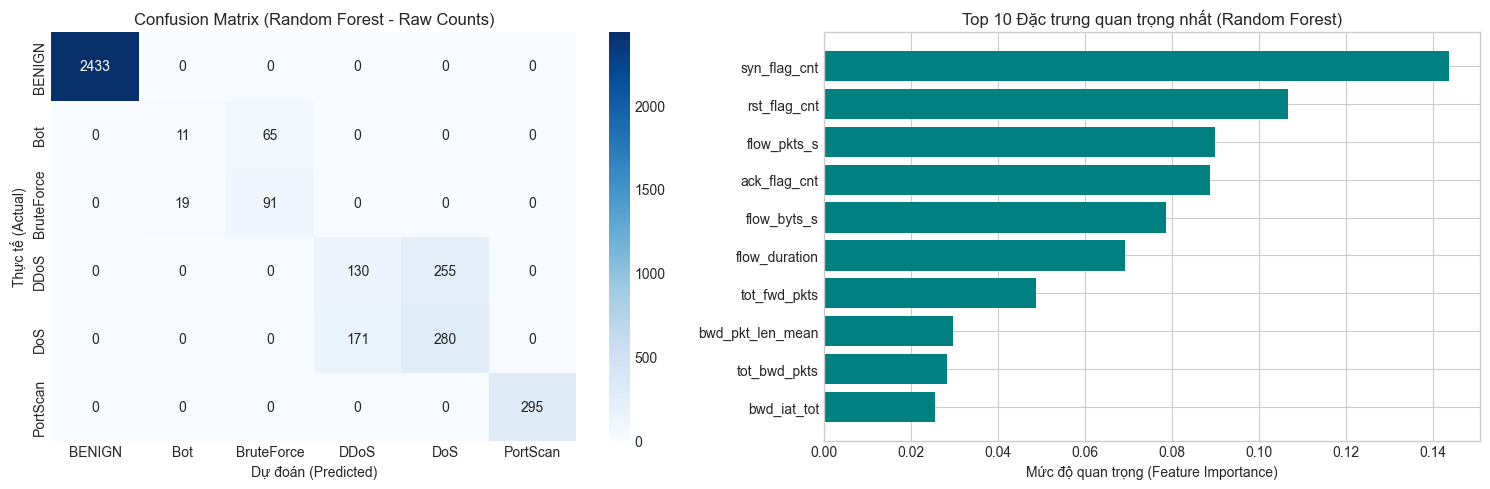

In [7]:
# Báo cáo chi tiết từng loại tấn công
print("\n--- Báo cáo Phân loại Chi tiết (Random Forest) ---")
print(classification_report(y_multi_test, y_pred_rf, target_names=class_names, digits=4))

# Vẽ Ma trận nhầm lẫn (Confusion Matrix)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
cm = confusion_matrix(y_multi_test, y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title("Confusion Matrix (Random Forest - Raw Counts)")
axes[0].set_xlabel("Dự đoán (Predicted)")
axes[0].set_ylabel("Thực tế (Actual)")

# Top 10 Đặc trưng quan trọng nhất trong Random Forest
importances = rf_clf.feature_importances_
top_indices = np.argsort(importances)[-10:]
axes[1].barh(range(len(top_indices)), importances[top_indices], color='teal')
axes[1].set_yticks(range(len(top_indices)))
axes[1].set_yticklabels([feature_cols[i] for i in top_indices])
axes[1].set_title("Top 10 Đặc trưng quan trọng nhất (Random Forest)")
axes[1].set_xlabel("Mức độ quan trọng (Feature Importance)")
plt.tight_layout()
plt.show()

## 6. STEP 8: Deep Learning với PyTorch
### 6.1. Deep Autoencoder cho Phát hiện Bất thường (Anomaly Detection)
Mạng Autoencoder chỉ được huấn luyện để nén và giải nén lưu lượng bình thường (`BENIGN`). Khi gặp lưu lượng tấn công, do cấu trúc khác biệt, sai số tái tạo (**Reconstruction Error**) $\|x - \hat{x}\|^2$ sẽ tăng vọt.

In [8]:
class Autoencoder(nn.Module):
    def __init__(self, input_dim, latent_dim=16):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Linear(64, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        x_recon = self.decoder(z)
        return x_recon

# Chuẩn bị DataLoader chỉ trên tập BENIGN
input_dim = X_train.shape[1]
ae_train_dataset = TensorDataset(torch.from_numpy(X_train_benign))
ae_train_loader = DataLoader(ae_train_dataset, batch_size=128, shuffle=True)

autoencoder = Autoencoder(input_dim=input_dim, latent_dim=16).to(device)
criterion_ae = nn.MSELoss()
optimizer_ae = optim.Adam(autoencoder.parameters(), lr=1e-3, weight_decay=1e-5)

print(f"[*] Đang huấn luyện Deep Autoencoder trên {len(X_train_benign):,} mẫu BENIGN...")
NUM_EPOCHS_AE = 15
loss_history = []

autoencoder.train()
for epoch in range(1, NUM_EPOCHS_AE + 1):
    total_loss = 0.0
    for batch in ae_train_loader:
        x_b = batch[0].to(device)
        optimizer_ae.zero_grad()
        recon = autoencoder(x_b)
        loss = criterion_ae(recon, x_b)
        loss.backward()
        optimizer_ae.step()
        total_loss += loss.item() * len(x_b)
    avg_loss = total_loss / len(X_train_benign)
    loss_history.append(avg_loss)
    if epoch % 5 == 0 or epoch == 1:
        print(f"  Epoch {epoch:02d}/{NUM_EPOCHS_AE} - Loss (MSE): {avg_loss:.6f}")

# Tính Reconstruction Error trên tập Val và Test
autoencoder.eval()
with torch.no_grad():
    X_val_t = torch.from_numpy(X_val).to(device)
    recon_val = autoencoder(X_val_t)
    scores_val_ae = torch.mean((recon_val - X_val_t) ** 2, dim=1).cpu().numpy()

    X_test_t = torch.from_numpy(X_test).to(device)
    recon_test = autoencoder(X_test_t)
    scores_test_ae = torch.mean((recon_test - X_test_t) ** 2, dim=1).cpu().numpy()

evaluate_anomaly_detector(scores_val_ae, y_bin_val, scores_test_ae, y_bin_test, "Deep Autoencoder")
torch.save(autoencoder.state_dict(), SAVED_MODELS_DIR / "autoencoder.pt")
print(f"[+] Đã lưu Autoencoder tại: {SAVED_MODELS_DIR / 'autoencoder.pt'}")

[*] Đang huấn luyện Deep Autoencoder trên 11,355 mẫu BENIGN...


  Epoch 01/15 - Loss (MSE): 0.247205


  Epoch 05/15 - Loss (MSE): 0.112576


  Epoch 10/15 - Loss (MSE): 0.077150


  Epoch 15/15 - Loss (MSE): 0.067813
=== Kết quả: Deep Autoencoder ===
  * Ngưỡng tối ưu (chọn từ Val): 0.1689
  * Accuracy:  98.40%
  * Precision: 98.09%
  * Recall:    97.34%
  * F1-Score:  97.71%
  * ROC-AUC:   0.9989
  * FPR:       1.03%
[+] Đã lưu Autoencoder tại: E:\project-ATTT\Machine-Learning-Based-Network-Intrusion-Detection-Using-Network-Traffic-Data\saved_models\autoencoder.pt


### 6.2. Mạng Nơ-ron Đa tầng (MLP Classifier) Phân loại Tấn công Đa lớp

In [9]:
class MLPClassifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, num_classes)
        )
        
    def forward(self, x):
        return self.net(x)

num_classes = len(class_names)
mlp_model = MLPClassifier(input_dim=input_dim, num_classes=num_classes).to(device)

# Huấn luyện có trọng số (Class Weights) cho hàm mất mát để xử lý tấn công hiếm
class_counts = np.bincount(y_multi_train)
weights = 1.0 / (class_counts + 1e-4)
weights = weights / np.sum(weights) * num_classes
weight_tensor = torch.tensor(weights, dtype=torch.float32).to(device)

criterion_mlp = nn.CrossEntropyLoss(weight=weight_tensor)
optimizer_mlp = optim.AdamW(mlp_model.parameters(), lr=2e-3, weight_decay=1e-4)

# DataLoader cho Train và Val
train_mlp_loader = DataLoader(TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_multi_train)), batch_size=128, shuffle=True)

print(f"[*] Đang huấn luyện Deep MLP Classifier ({num_classes} lớp)...")
NUM_EPOCHS_MLP = 15
for epoch in range(1, NUM_EPOCHS_MLP + 1):
    mlp_model.train()
    total_loss = 0.0
    for x_b, y_b in train_mlp_loader:
        x_b, y_b = x_b.to(device), y_b.to(device).long()
        optimizer_mlp.zero_grad()
        logits = mlp_model(x_b)
        loss = criterion_mlp(logits, y_b)
        loss.backward()
        optimizer_mlp.step()
        total_loss += loss.item() * len(x_b)
    if epoch % 5 == 0 or epoch == 1:
        print(f"  Epoch {epoch:02d}/{NUM_EPOCHS_MLP} - Loss: {total_loss / len(X_train):.4f}")

# Đánh giá trên tập Test
mlp_model.eval()
with torch.no_grad():
    test_logits = mlp_model(torch.from_numpy(X_test).to(device))
    y_pred_mlp = torch.argmax(test_logits, dim=1).cpu().numpy()

acc_mlp = accuracy_score(y_multi_test, y_pred_mlp)
macro_f1_mlp = f1_score(y_multi_test, y_pred_mlp, average='macro', zero_division=0)

model_results["Deep MLP"] = {
    'Model': 'Deep MLP Classifier',
    'Task': 'Supervised Multi-class',
    'Accuracy': acc_mlp,
    'Precision': precision_score(y_multi_test, y_pred_mlp, average='macro', zero_division=0),
    'Recall': recall_score(y_multi_test, y_pred_mlp, average='macro', zero_division=0),
    'F1-Score': macro_f1_mlp,
    'ROC-AUC': np.nan,
    'FPR': np.nan
}
print(f"=== Kết quả: Deep MLP Classifier ===")
print(f"  * Overall Accuracy: {acc_mlp*100:.2f}%")
print(f"  * Macro F1-Score:   {macro_f1_mlp*100:.2f}%")
torch.save(mlp_model.state_dict(), SAVED_MODELS_DIR / "mlp_classifier.pt")

[*] Đang huấn luyện Deep MLP Classifier (6 lớp)...


  Epoch 01/15 - Loss: 0.6404


  Epoch 05/15 - Loss: 0.4726


  Epoch 10/15 - Loss: 0.4612


  Epoch 15/15 - Loss: 0.4596
=== Kết quả: Deep MLP Classifier ===
  * Overall Accuracy: 86.08%
  * Macro F1-Score:   60.37%


## 7. Bảng So sánh Tổng thể & Đánh giá Hiệu năng các Mô hình

BẢNG TỔNG KẾT HIỆU NĂNG CÁC MÔ HÌNH (STEP 6 - STEP 8)
                  Model                       Task  Accuracy  Precision   Recall  F1-Score  ROC-AUC      FPR
  Gaussian Distribution Anomaly Detection (Binary)  0.998400   0.997722 0.997722  0.997722 0.999991 0.001233
       Isolation Forest Anomaly Detection (Binary)  0.996533   0.993939 0.996203  0.995070 0.999922 0.003288
          Random Forest     Supervised Multi-class  0.864000   0.650876 0.655086  0.639786      NaN      NaN
XGBoost / GradientBoost     Supervised Multi-class  0.860000   0.659129 0.659404  0.658787      NaN      NaN
       Deep Autoencoder Anomaly Detection (Binary)  0.984000   0.980872 0.973424  0.977134 0.998946 0.010275
    Deep MLP Classifier     Supervised Multi-class  0.860800   0.593004 0.662670  0.603703      NaN      NaN

[+] Đã lưu bản tổng kết kết quả tại: E:\project-ATTT\Machine-Learning-Based-Network-Intrusion-Detection-Using-Network-Traffic-Data\outputs\model_comparison_summary.json


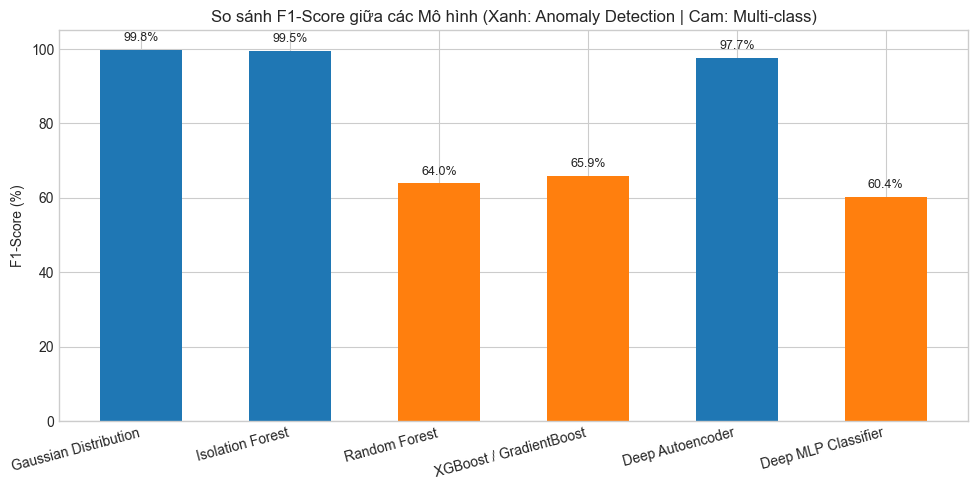

In [10]:
# Tổng hợp kết quả thành DataFrame
df_results = pd.DataFrame(model_results.values())
metrics_cols = ['Model', 'Task', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'FPR']
df_display = df_results[metrics_cols].copy()

print("=" * 85)
print("BẢNG TỔNG KẾT HIỆU NĂNG CÁC MÔ HÌNH (STEP 6 - STEP 8)")
print("=" * 85)
print(df_display.to_string(index=False))

# Xuất kết quả ra file JSON phục vụ báo cáo khoa học
summary_path = PROJECT_ROOT / "outputs" / "model_comparison_summary.json"
summary_path.parent.mkdir(parents=True, exist_ok=True)
with open(summary_path, 'w', encoding='utf-8') as f:
    json.dump(model_results, f, indent=2, ensure_ascii=False)
print(f"\n[+] Đã lưu bản tổng kết kết quả tại: {summary_path}")

# Vẽ đồ thị so sánh F1-Score
plt.figure(figsize=(10, 5))
colors = ['#1f77b4' if 'Binary' in t else '#ff7f0e' for t in df_results['Task']]
bars = plt.bar(df_results['Model'], df_results['F1-Score'] * 100, color=colors, width=0.55)
plt.title("So sánh F1-Score giữa các Mô hình (Xanh: Anomaly Detection | Cam: Multi-class)", fontsize=12)
plt.ylabel("F1-Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=15, ha='right')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.1f}%", ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 8. Xuất Metadata & Preprocessing Pipeline cho Module Real-Time
Để phục vụ **STEP 11 (Phát hiện thời gian thực trên Kali Linux)**, chúng ta lưu lại `scaler`, `feature_cols`, `label_encoder`, và các ngưỡng tối ưu.

In [11]:
# Lưu scaler và metadata
joblib.dump(scaler, SAVED_MODELS_DIR / "scaler.joblib")
metadata = {
    'feature_names': feature_cols,
    'class_names': class_names,
    'num_features': len(feature_cols),
    'models_trained': list(model_results.keys()),
    'timestamp': time.strftime("%Y-%m-%d %H:%M:%S")
}
with open(SAVED_MODELS_DIR / "metadata.json", 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

print("[+] Hoàn tất! Tất cả mô hình, scaler và siêu tham số đã được lưu tại thư mục:")
print(f"    {SAVED_MODELS_DIR}")
for p in SAVED_MODELS_DIR.iterdir():
    if p.is_file():
        print(f"     - {p.name} ({p.stat().st_size / 1024:.1f} KB)")

[+] Hoàn tất! Tất cả mô hình, scaler và siêu tham số đã được lưu tại thư mục:
    E:\project-ATTT\Machine-Learning-Based-Network-Intrusion-Detection-Using-Network-Traffic-Data\saved_models
     - .gitkeep (0.0 KB)
     - autoencoder.pt (46.2 KB)
     - botnet_graph_rf.joblib (105.3 KB)
     - gradient_boosting.joblib (1216.3 KB)
     - isolation_forest.joblib (26527.4 KB)
     - metadata.json (0.9 KB)
     - mlp_classifier.pt (55.0 KB)
     - random_forest.joblib (12877.0 KB)
     - scaler.joblib (0.8 KB)


## 9. STEP 9: Phát hiện Cấu trúc Liên kết Botnet bằng Đồ thị Giao tiếp Mạng (Centralized C2 vs P2P)
Sử dụng module `graph.botnet_graph` để:
- Dựng đồ thị giao tiếp có hướng $G = (V, E)$ giữa các host.
- Trích xuất 20 đặc trưng đồ thị cấp nút (In/Out-Degree, PageRank, Clustering Coefficient, Betweenness Centrality, Reciprocity Ratio, Beaconing Edges).
- Nhận diện cấu trúc **Centralized (C2 Star/Hub-and-Spoke)** và **Peer-to-Peer (P2P Mesh)**.
- So sánh hiệu quả của 6 thuật toán (Graph Heuristic, Gaussian Anomaly, Isolation Forest, Random Forest, Gradient Boosting, MLP) trên không gian đặc trưng đồ thị.

C:\Users\MIRINDA\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


=== KẾT QUẢ PHÁT HIỆN CẤU TRÚC ĐỒ THỊ BOTNET ===
  * Cấu trúc phát hiện : HYBRID
  * Quy mô đồ thị      : 124 nút (IP), 388 cạnh có hướng
  * Máy chủ C2 phát hiện (1): ['203.0.113.200']
  * Centralized Bots   : 20 hosts
  * P2P Mesh Bots      : 15 hosts

=== BẢNG SO SÁNH CÁC THUẬT TOÁN ML TRÊN ĐẶC TRƯNG ĐỒ THỊ BOTNET ===
                    Model          Category  Accuracy  Precision  Recall  F1-Score  ROC-AUC     FPR
 Graph Topology Heuristic Unsupervised Rule  1.000000   1.000000     1.0   1.00000 1.000000 0.00000
 Gaussian Anomaly (Graph)   Unsupervised ML  1.000000   1.000000     1.0   1.00000 1.000000 0.00000
 Isolation Forest (Graph)   Unsupervised ML  0.886364   0.722222     1.0   0.83871 0.863524 0.16129
    Random Forest (Graph)     Supervised ML  1.000000   1.000000     1.0   1.00000 1.000000 0.00000
Gradient Boosting (Graph)     Supervised ML  1.000000   1.000000     1.0   1.00000 1.000000 0.00000
   MLP Neural Net (Graph)     Supervised DL  1.000000   1.000000     1.0   1.

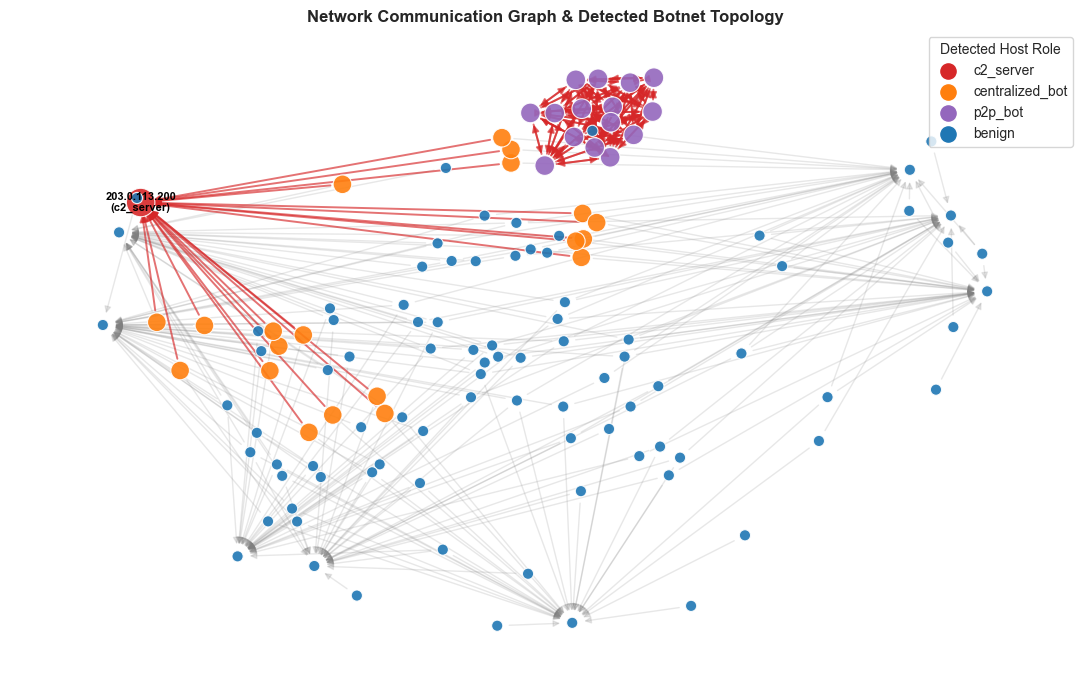

In [12]:
sys.path.insert(0, str(PROJECT_ROOT))
from graph.botnet_graph import (
    generate_synthetic_botnet_flows,
    run_pipeline,
    plot_botnet_graph,
)

# Sinh kịch bản mạng kết hợp cả Botnet Tập trung (Centralized C2) và Ngang hàng (P2P)
flows_botnet, gt_roles = generate_synthetic_botnet_flows(
    scenario='hybrid', n_benign_hosts=80, n_centralized_bots=20, n_p2p_bots=15, seed=SEED
)
graph_res = run_pipeline(flows_botnet, gt_roles=gt_roles, save_outputs=True)
topo = graph_res['summary']

print("=== KẾT QUẢ PHÁT HIỆN CẤU TRÚC ĐỒ THỊ BOTNET ===")
print(f"  * Cấu trúc phát hiện : {topo['topology_type'].upper()}")
print(f"  * Quy mô đồ thị      : {topo['n_nodes']} nút (IP), {topo['n_edges']} cạnh có hướng")
print(f"  * Máy chủ C2 phát hiện ({len(topo['c2_servers'])}): {topo['c2_servers']}")
print(f"  * Centralized Bots   : {len(topo['centralized_bots'])} hosts")
print(f"  * P2P Mesh Bots      : {len(topo['p2p_bots'])} hosts")

print("\n=== BẢNG SO SÁNH CÁC THUẬT TOÁN ML TRÊN ĐẶC TRƯNG ĐỒ THỊ BOTNET ===")
print(graph_res['comparison_df'].to_string(index=False))

# Vẽ trực quan hóa đồ thị giao tiếp mạng
fig = plot_botnet_graph(graph_res['graph'], graph_res['annotated_df'])
plt.show()